# State of the art: outcome-testing toolkits, conformal libraries, explainers and fairness libraries

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 01 to 07 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- name the open toolkits that offer outcome tests, label-free monitoring, conformal prediction, explainers and fairness metrics, say under which licence each can be used by a product of this kind, and say which tests of the ECB instructions none of them implements;
- compare the engine's split-conformal quantile with the one the MAPIE 1.5.0 package returns, run, and count on a grid how often they return different order statistics;
- check the engine's two-proportion z test and Fisher test against independent identities of SciPy, and its selection rates, parity difference and parity ratio against fairlearn 0.15.0 running on the committed HMDA counts;
- say which parts of this notebook were run and which could not be: NannyML and SHAP are not in this notebook environment, so their results are not reproduced here.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 mapie==1.5.0 fairlearn==0.15.0 scikit-learn==1.9.1
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the packages and print their versions
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.fairness import inference, metrics
from riskvalidation.ml import conformal
from scipy import stats

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "scipy", "matplotlib", "mapie", "fairlearn", "scikit-learn"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2
mapie 1.5.0
fairlearn 0.15.0
scikit-learn 1.9.1


## Data

- **The engine's catalogue** of validation tests (`riskvalidation.catalogue()`), to count what the engine implements for machine-learning and fairness validation.
- **The committed calibration size of case C20** (`data/derived/C20/fed-shift.json`): the conformal windows of the Federal Reserve shift variant use a calibration window of 1,471 companies. The notebook uses only that number, and draws random scores of that size.
- **The committed HMDA counts of case C21** (`data/derived/C21/pair-2018-19.json`): the favourable count and the size of each race group of Delaware 2018, to compare the engine's tests of two rates with independent identities.

No new raw data is needed. (The scores of the conformal scan are random draws of the committed size with a fixed seed; nothing else is generated.) Both documents are read for their numbers and their baking engine version, printed below.

In [2]:
# Count the engine's ML and fairness tests and read the two committed documents' engine version and sizes
catalogue = rv.catalogue()
by_family = {}
for spec in catalogue:
    by_family[spec.family] = by_family.get(spec.family, 0) + 1
print("tests in the catalogue:", len(catalogue), "| ml:", by_family["ml"], "| fairness:", by_family["fairness"])
fed = json.loads((ROOT / "data" / "derived" / "C20" / "fed-shift.json").read_text(encoding="utf-8"))
hmda = json.loads((ROOT / "data" / "derived" / "C21" / "pair-2018-19.json").read_text(encoding="utf-8"))
print("C20 baked with riskvalidation", fed["provenance"]["riskvalidation_version"], "| C21", hmda["provenance"]["riskvalidation_version"])
n_cal = next(t for t in fed["tests"] if t["test_id"] == "ml.conformal_coverage")["extras"]["n_cal"]
print("committed calibration window:", n_cal)

tests in the catalogue: 129 | ml: 13 | fairness: 12
C20 baked with riskvalidation 0.8.1 | C21 0.8.1
committed calibration window: 1471


## Method

The comparison has two rules. **Reproduce where a pinned reference allows**: the reference package, an independent implementation or an identity that holds between two formulas is run, and the difference is reported with its tolerance and the source of the difference. **Say what was not run**: a library that is not in the notebook environment is not imported, and its result is not reproduced. MAPIE 1.5.0, fairlearn 0.15.0 and the scikit-learn 1.9.1 that both need are installed here at exact pins; NannyML and SHAP are not.

### The split-conformal quantile against MAPIE

For $n$ calibration scores $s_{(1)} \le \dots \le s_{(n)}$ the exact conformal quantile is the order statistic $s_{(k)}$ with $k = \lceil (n+1)(1-\alpha) \rceil$ (notebook 04). The engine computes $k$ on the exact decimal of $\alpha$. The reference is the package itself, run: the `SplitConformalRegressor` of MAPIE 1.5.0 with a prefit estimator that always predicts 0, so that the absolute residuals it conformalises are the calibration scores and the upper end of its interval around that prediction is its quantile. Two other rules are shown beside it. The first is the NumPy call

$$\hat q_{\text{NumPy}} = \texttt{np.quantile}\bigl(s,\; (n+1)(1-\alpha)/n,\; \texttt{method="higher"}\bigr)$$

(the level capped at 1), which an earlier reading of the MAPIE code attributed to the package and which the engine's documentation names as not the reference: it can return $s_{(k+1)}$ where the exact rule returns $s_{(k)}$. The second is the naive float rule, $s_{(\lceil (n+1)(1-\alpha) \rceil)}$ with the product taken in floats.

The next cell draws random scores of the committed calibration size (seeded; the committed file gives only the size), applies the four rules at $\alpha = 0.1$ and prints the order statistic each returns. Then it scans the grid $n = 5, \dots, 399$ and $\alpha = 0.01, \dots, 0.99$ and counts the pairs in which each rule differs from the engine. MAPIE refuses a pair when its own check fails, which its error message states as the number of scores being below $1/\alpha$ or $1/(1-\alpha)$; the cell counts those refusals apart from the differences and checks that every pair MAPIE refuses and the engine answers satisfies that stated condition. The tolerance is exact equality of the returned score: every rule returns one of the calibration scores, so a difference is a different order statistic, never a rounding.

In [3]:
# The four rules at the committed calibration size, then a grid scan of how often each differs from the engine
import collections

from mapie.regression import SplitConformalRegressor
from sklearn.dummy import DummyRegressor


def mapie_quantile(scores, alpha):
    """The upper end of the interval MAPIE 1.5.0 builds around a prediction of 0 when `scores` are its absolute residuals; None when MAPIE refuses the pair (alpha, n)."""
    estimator = DummyRegressor(strategy="constant", constant=0.0).fit(np.zeros((2, 1)), np.zeros(2))
    splitter = SplitConformalRegressor(estimator=estimator, confidence_level=1 - alpha, prefit=True)
    splitter.conformalize(np.zeros((scores.size, 1)), scores)
    try:
        _, interval = splitter.predict_interval(np.zeros((1, 1)))
    except ValueError:
        return None
    return float(interval[0, 1, 0])


rng = np.random.default_rng(3)
scores = np.sort(rng.random(n_cal))
alpha = 0.1
engine_q = conformal.split_conformal_quantile(scores, alpha)
mapie_q = mapie_quantile(scores, alpha)
numpy_q = np.quantile(scores, min(1.0, (n_cal + 1) * (1 - alpha) / n_cal), method="higher")
naive_q = scores[math.ceil((n_cal + 1) * (1 - alpha)) - 1]
rank = lambda q: int(np.searchsorted(scores, q)) + 1
print("n_cal", n_cal, "| rank of the engine quantile", rank(engine_q), "| MAPIE package", rank(mapie_q), "| NumPy higher call", rank(numpy_q), "| naive float rule", rank(naive_q))
count = collections.Counter()
for n in range(5, 400):
    s = np.sort(rng.random(n))
    for a in np.arange(1, 100) / 100:
        count["pairs"] += 1
        engine = conformal.split_conformal_quantile(s, float(a))
        mapie_value = mapie_quantile(s, float(a))
        if math.isinf(engine):
            count["engine has no finite quantile"] += 1
            count["... and MAPIE refuses too"] += int(mapie_value is None)
            continue
        count["NumPy higher call differs"] += int(np.quantile(s, min(1.0, (n + 1) * (1 - a) / n), method="higher") != engine)
        count["naive float rule differs"] += int(s[min(math.ceil((n + 1) * (1 - a)), n) - 1] != engine)
        if mapie_value is None:
            count["MAPIE refuses, engine answers"] += 1
            count["... and n is below 1/alpha or 1/(1-alpha)"] += int(n < max(1 / a, 1 / (1 - a)))
        else:
            count["compared with the MAPIE package"] += 1
            if mapie_value != engine:
                count["MAPIE package differs"] += 1
                count["... and equals the naive float rule"] += int(mapie_value == s[min(math.ceil((n + 1) * (1 - a)), n) - 1])
                count["... and is the next order statistic above"] += int(np.searchsorted(s, mapie_value) == np.searchsorted(s, engine) + 1)
for key, value in count.items():
    print(f"{key:44s} {value:7d}")


n_cal 1471 | rank of the engine quantile 1325 | MAPIE package 1325 | NumPy higher call 1325 | naive float rule 1325
pairs                                          39105
engine has no finite quantile                    249
... and MAPIE refuses too                        249
NumPy higher call differs                      19525
naive float rule differs                         231
MAPIE refuses, engine answers                    289
... and n is below 1/alpha or 1/(1-alpha)        289
compared with the MAPIE package                38567
MAPIE package differs                            227
... and equals the naive float rule              227
... and is the next order statistic above        227


## State of the art

### What exists, and under which licence

The research dossier on model risk (verified on 2026-10-04 on the GitHub and PyPI records; licences read from the licence files, not legal advice) finds these open tools. The column "usable" says whether a product under a permissive licence can **depend** on the package; AGPL, GPL and BSL tools are cited and compared, never imported.

| Tool | What it offers (outcome and model tests) | Licence | Usable as a dependency |
|---|---|---|---|
| PiML-Toolbox (Wells Fargo origin) | accuracy, explainability (PFI, PDP, ALE, SHAP), WeakSpot, Overfit, Reliability (split conformal), Robustness, Resilience | Apache-2.0 | licence yes; frozen since 2025 and shipped as binary wheels, so only as a cross-check |
| ValidMind library | data and model validation tests, ongoing monitoring, documentation | AGPL-3.0 or commercial | no |
| BBVA mercury-robust | data and model test suites: drift, label leaking, cohort performance | Apache-2.0 | yes |
| ING probatus | SHAP-based interpretation, `sample_similarity` (resemblance model) | MIT | yes |
| ING popmon, Evidently | population shift monitoring, drift tests (KS, chi-square, PSI) and data quality | MIT, Apache-2.0 | yes |
| NannyML | confidence-based performance estimation (CBPE), drift | Apache-2.0 | yes, with a maintenance caveat |
| MAPIE | conformal prediction (split, CV+, jackknife+, conformalized quantile regression, risk control) | BSD-3-Clause | yes |
| fairlearn | fairness assessment (MetricFrame, parity and equalized-odds differences and ratios) and mitigation | MIT | yes |
| SHAP, InterpretML | Shapley explanations (TreeSHAP), glass-box EBM | MIT | yes (the pipeline uses SHAP; the engine never imports it) |
| deepchecks, alibi, dalex | validation suites and explainers | AGPL-3.0, BSL 1.1, GPL-3.0 | no |

The dossier's finding that matters for the engine: **no toolkit found implements the ECB Jeffreys, MWB, migration z-tests, HHI-CV test or generalised AUC exactly as specified** (these belong to the credit-risk topics of this set), and none of the toolkits above reports the **size and the power** of its tests. The conformal ideas the dossier lists beyond the split form (conformalized quantile regression, jackknife+, Venn-Abers calibrated probabilities) are in the literature and in MAPIE; the engine implements the split form.

### What the engine implements, by comparison

The engine's catalogue (cell above) holds the tests of this topic: ML (robustness, resilience, seeds, reason codes, explainer agreement, additivity, overfit, weak spots, conformal coverage, leakage, data quality, the CBPE estimate and the challenger Brier) and fairness (selection rates, parity, adverse impact, the two-rate tests, equalized odds, equal opportunity, calibration and AUC by group, conditional disparity, rate spread, replication, situation testing). What it adds to a toolkit is the way each is stated: a null hypothesis, an engine policy with a light, a null law that takes the calibration size into account (notebook 04) and an exact permutation reference (notebook 02). The next cells reproduce the part of that comparison that the notebook environment can run.

### The two-rate tests against independent identities

For two groups with $x_1$ of $n_1$ and $x_2$ of $n_2$, the squared pooled z statistic equals Pearson's chi-square statistic of the $2 \times 2$ table **without continuity correction**, and its p-value equals that of the chi-square test with one degree of freedom. Fisher's exact test is the hypergeometric test of SciPy's `fisher_exact`. The next cell checks both identities on the five contrasts of the committed HMDA race attribute, and the parity difference against the definition used by fairlearn's `demographic_parity_difference` for two groups, the largest minus the smallest selection rate.

In [4]:
# Check the z test against Pearson chi-square, Fisher against SciPy, and the parity difference against max minus min of the selection rates
race = hmda["outputs"]["attributes"][0]
groups = {g["group"]: (g["n_approved"], g["n"]) for g in race["groups"]}
x_ref, n_ref = groups[race["reference_group"]]
print(f'{"group":44s} {"z²":>10s} {"chi-square":>11s} {"p z":>10s} {"p chi-square":>15s} {"p Fisher, engine":>19s} {"p Fisher, SciPy":>18s}')
for name, (x, n) in groups.items():
    if name == race["reference_group"]:
        continue
    z = inference.two_proportion_z_test(x, n, x_ref, n_ref)
    table = [[x, n - x], [x_ref, n_ref - x_ref]]
    chi2, p_chi2, _, _ = stats.chi2_contingency(table, correction=False)
    fisher = inference.fisher_exact_test(x, n, x_ref, n_ref)
    p_scipy = stats.fisher_exact(table).pvalue
    print(f"{name:44s} {z.statistic ** 2:10.3f} {chi2:11.3f} {z.p_value:10.3e} {p_chi2:15.3e} {fisher.p_value:19.3e} {p_scipy:18.3e}")
rates = metrics.group_selection_rates(np.r_[np.ones(60), np.zeros(40), np.ones(75), np.zeros(25)].astype(int), np.r_[np.repeat("A", 100), np.repeat("B", 100)])
spread = max(r.rate for r in rates.values()) - min(r.rate for r in rates.values())
print("parity difference for two groups, engine:", abs(metrics.demographic_parity_difference(rates, "B")["A"]), "| largest minus smallest rate:", round(spread, 12))

group                                                z²  chi-square        p z    p chi-square    p Fisher, engine    p Fisher, SciPy
American Indian or Alaska Native                 55.357      55.357  1.005e-13       1.005e-13           1.208e-11          1.208e-11
Asian                                             1.140       1.140  2.857e-01       2.857e-01           2.857e-01          2.857e-01
Black or African American                       581.966     581.966 1.401e-128      1.401e-128          2.998e-120         2.998e-120
Native Hawaiian or Other Pacific Islander        18.503      18.503  1.696e-05       1.696e-05           7.363e-05          7.363e-05
2 or more minority races                         42.695      42.695  6.399e-11       6.399e-11           3.030e-09          3.030e-09
parity difference for two groups, engine: 0.15 | largest minus smallest rate: 0.15


### The selection-rate metrics against fairlearn 0.15.0

fairlearn defines the demographic parity difference as the largest minus the smallest selection rate over the groups, and its ratio as the smallest over the largest. The engine states both against a chosen reference group. When the reference group has the highest rate, as White does in the committed HMDA race attribute, the engine's largest absolute difference equals fairlearn's difference and the engine's smallest ratio equals fairlearn's ratio. The next cell turns the committed counts of the six listed race groups into one decision per applicant (approved or denied: the counts fix the decisions up to their order, and the metrics do not depend on the order), runs fairlearn's `MetricFrame` and its two parity functions on them, and prints the engine's value beside each with the absolute difference. The tolerance is $10^{-12}$: both sides divide the same integers, so only the order of the floating-point operations may differ.

fairlearn's equalized-odds and equal-opportunity differences need true labels as well as decisions, and the committed C21 document holds counts of approvals per group and no outcomes, so those two are not reproduced.

In [5]:
# fairlearn 0.15.0 on the committed HMDA counts: the selection rate per group, the parity difference and the parity ratio, beside the engine
from fairlearn.metrics import MetricFrame, demographic_parity_difference, demographic_parity_ratio, selection_rate

names = [g["group"] for g in race["groups"]]
decision = np.concatenate([np.r_[np.ones(groups[name][0]), np.zeros(groups[name][1] - groups[name][0])] for name in names]).astype(int)
membership = np.concatenate([np.repeat(name, groups[name][1]) for name in names])
engine_rates = metrics.group_selection_rates(decision, membership)
frame = MetricFrame(metrics=selection_rate, y_true=decision, y_pred=decision, sensitive_features=membership)
print(f"{'group':44s} {'engine rate':>12s} {'fairlearn rate':>15s} {'|difference|':>13s}")
for name in names:
    print(f"{name:44s} {engine_rates[name].rate:12.6f} {frame.by_group[name]:15.6f} {abs(engine_rates[name].rate - frame.by_group[name]):13.2e}")
highest = max(engine_rates, key=lambda g: engine_rates[g].rate)
print("reference group of the committed attribute:", race["reference_group"], "| group with the highest rate:", highest)
engine_difference = max(abs(v) for v in metrics.demographic_parity_difference(engine_rates, highest).values())
engine_ratio = min(v for v in metrics.demographic_parity_ratio(engine_rates, highest).values())
fl_difference = demographic_parity_difference(decision, decision, sensitive_features=membership)
fl_ratio = demographic_parity_ratio(decision, decision, sensitive_features=membership)
print(f"parity difference: engine {engine_difference:.12f} | fairlearn {fl_difference:.12f} | |difference| {abs(engine_difference - fl_difference):.2e}")
print(f"parity ratio:      engine {engine_ratio:.12f} | fairlearn {fl_ratio:.12f} | |difference| {abs(engine_ratio - fl_ratio):.2e}")
print("within the tolerance of 1e-12:", all(abs(engine_rates[n].rate - frame.by_group[n]) < 1e-12 for n in names) and abs(engine_difference - fl_difference) < 1e-12 and abs(engine_ratio - fl_ratio) < 1e-12)


group                                         engine rate  fairlearn rate  |difference|
American Indian or Alaska Native                 0.510791        0.510791      0.00e+00
Asian                                            0.763061        0.763061      0.00e+00
Black or African American                        0.617318        0.617318      0.00e+00
Native Hawaiian or Other Pacific Islander        0.581395        0.581395      0.00e+00
White                                            0.775491        0.775491      0.00e+00
2 or more minority races                         0.494737        0.494737      0.00e+00
reference group of the committed attribute: White | group with the highest rate: White
parity difference: engine 0.280754040042 | fairlearn 0.280754040042 | |difference| 5.55e-17
parity ratio:      engine 0.637966033508 | fairlearn 0.637966033508 | |difference| 0.00e+00
within the tolerance of 1e-12: True


### What was run with the packages, and what could not be

The engine's own test suite compares with MAPIE and fairlearn under its `ml` extra (`mapie>=1.5,<2`, `fairlearn>=0.15,<0.16`). This notebook environment pins `mapie==1.5.0`, `fairlearn==0.15.0` and `scikit-learn==1.9.1` (the pipeline's pin, which both need), so the two comparisons above run the packages themselves. What remains not run: fairlearn's equalized-odds and equal-opportunity differences, because the committed C21 document holds approval counts per group and no outcomes with true labels; and NannyML and SHAP, which are not in the environment: the CBPE formula of the engine is the one the NannyML documentation gives (notebook 04), and the equality of the numbers was not tested here.

### The evidence, drawn

The figure shows the grid of the Method: for each calibration size, the share of the 99 values of $\alpha$ for which the NumPy `higher` call and the naive float rule return an order statistic different from the engine's; the share of answered pairs for which the MAPIE package differs from the engine; and the share of the 99 values for which MAPIE refuses a pair that the engine answers.

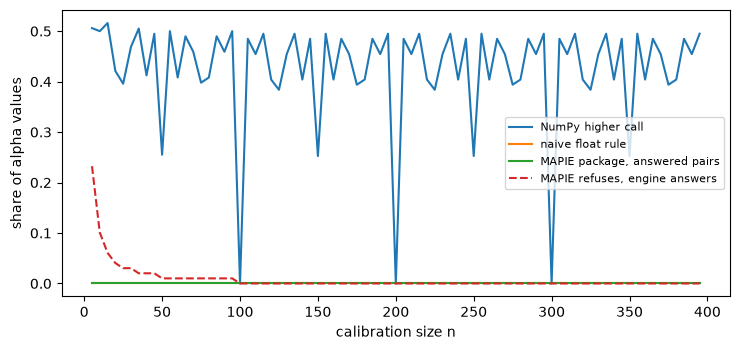

In [6]:
# For each calibration size the share of alpha values at which each rule differs from the engine, and the share at which MAPIE refuses
sizes = list(range(5, 400, 5))
share_numpy, share_naive, share_mapie, share_refused = [], [], [], []
for n in sizes:
    s = np.sort(rng.random(n))
    alphas = np.arange(1, 100) / 100
    engine = np.array([conformal.split_conformal_quantile(s, float(a)) for a in alphas])
    numpy_rule = np.array([np.quantile(s, min(1.0, (n + 1) * (1 - a) / n), method="higher") for a in alphas])
    naive = np.array([s[min(math.ceil((n + 1) * (1 - a)), n) - 1] for a in alphas])
    mapie_values = [mapie_quantile(s, float(a)) for a in alphas]
    finite = np.isfinite(engine)
    answered = np.array([v is not None for v in mapie_values])
    both = finite & answered
    mapie_array = np.array([np.nan if v is None else v for v in mapie_values])
    share_numpy.append(float(np.mean(numpy_rule[finite] != engine[finite])))
    share_naive.append(float(np.mean(naive[finite] != engine[finite])))
    share_mapie.append(float(np.mean(mapie_array[both] != engine[both])) if both.any() else float("nan"))
    share_refused.append(float(np.mean(finite & ~answered)))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(sizes, share_numpy, label="NumPy higher call")
ax.plot(sizes, share_naive, label="naive float rule")
ax.plot(sizes, share_mapie, label="MAPIE package, answered pairs")
ax.plot(sizes, share_refused, linestyle="--", label="MAPIE refuses, engine answers")
ax.set_xlabel("calibration size n")
ax.set_ylabel("share of alpha values")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## Results

- **The engine's catalogue holds 129 tests, 13 for machine-learning validation and 12 for fairness.** The dossier's survey of open toolkits finds outcome tests (PiML, mercury-robust, ValidMind), label-free monitoring (NannyML, popmon, Evidently), conformal libraries (MAPIE), explainers (SHAP, InterpretML) and fairness libraries (fairlearn), under licences from MIT to AGPL; the ones under AGPL, GPL and BSL are compared and not imported. None reports the size and the power of its tests, and none implements the ECB credit-risk tests as specified, which is the gap the dossier records and the engine fills for the tests of this topic with a stated null, a policy light and, for two of them, a corrected null law (notebooks 02 and 04).
- **At the committed calibration size the rules agree.** For 1,471 scores at $\alpha = 0.1$ the engine, the MAPIE package, the NumPy `higher` call and the naive float rule all return the score of rank 1,325, the rank $k$ of the committed C20 windows.
- **Across the grid they do not agree everywhere.** The grid has 39,105 pairs $(n, \alpha)$ with $n$ from 5 to 399. In 249 of them $n$ is too small for $\alpha$ and the engine returns no finite quantile; MAPIE refuses all 249 as well. In 289 pairs MAPIE refuses and the engine answers, and every one of the 289 has $n$ below $1/\alpha$ or $1/(1-\alpha)$, the condition MAPIE's own message states. In the 38,567 pairs where both answer, the MAPIE package returns the engine's score in 38,340 and a different one in 227 (0.59%). In each of the 227 it returns exactly the score of the naive float rule, one order statistic above the engine's, a more conservative quantile. That matches the floating-point trap of notebook 04 (the naive rule differs from the engine in 231 pairs, 0.6%) and is consistent with MAPIE taking its rank in floating point; the cell does not read MAPIE's code, so the cause is inferred from the match and not shown. The NumPy `higher` call, which an earlier version of this notebook attributed to MAPIE, differs from the engine in 19,525 pairs (49.9%) and is not what the package returns.
- **The tests of two rates match independent identities.** For the five HMDA race contrasts the squared pooled z statistic equals Pearson's chi-square without continuity correction to the printed digits (for example 581.966 for the Black against the White group), their p-values are equal (1.401e-128), and the engine's Fisher p-values equal SciPy's. The engine's parity difference for two groups, 0.15, equals the largest minus the smallest selection rate, the definition of fairlearn's difference.
- **fairlearn 0.15.0 agrees on the committed HMDA counts.** The selection rates of the six race groups are identical to the printed digits (difference 0). The parity difference, 0.280754, and the parity ratio, 0.637966, differ from the engine's by at most 5.6e-17, inside the tolerance of 1e-12; White is the group with the highest rate, so the engine's largest difference and smallest ratio against it are fairlearn's definitions. The equalized-odds and equal-opportunity differences are not reproduced: the committed document holds counts of approvals, not outcomes with true labels. Both documents were baked with riskvalidation 0.8.1.
- **What was not run.** NannyML and SHAP are not in the notebook environment, so nothing here reproduces their results; MAPIE and fairlearn are, at the pins `mapie==1.5.0` and `fairlearn==0.15.0`, and their results above come from the packages.

What the results do not show: that the engine is better than any of these tools. They show what each does and does not state, and where an independent identity or a NumPy rule can be checked; the licence column is a reading of the dossier and not legal advice.

## Summary

- The open toolkits cover outcome tests, label-free monitoring, conformal prediction, explainers and fairness metrics under licences from MIT to AGPL; none reports the size and power of its tests, and none implements the ECB credit-risk tests as specified.
- The engine holds 13 machine-learning and 12 fairness tests, each with a stated null, a policy light and the convention that sets it.
- The MAPIE 1.5.0 package returns the engine's split-conformal score in 38,340 of the 38,567 pairs where both answer; in the other 227 (0.59%) it returns the naive float rule's score, one order statistic above, and in 289 further pairs it refuses where the engine answers. The NumPy `higher` call differs from the engine in 49.9% of the grid and is not MAPIE's rule.
- The engine's two-rate tests equal the Pearson chi-square (without continuity correction) and SciPy's Fisher test, and fairlearn 0.15.0 gives the same selection rates, parity difference and parity ratio on the committed HMDA counts to 5.6e-17.
- NannyML and SHAP are not in the notebook environment and are not run; fairlearn's equalized-odds differences need outcomes the committed data does not hold.

**What to try next.** Notebook 09 measures, with the engine's own plants, how often these tests fire when nothing is wrong and how often they find what was planted, and shows the corrections of the conformal and shift tests.

## References

- PiML-Toolbox (Apache-2.0), outcome tests WeakSpot, Overfit, Reliability, Robustness and Resilience; Sudjianto et al. (2023), arXiv 2305.04214. https://github.com/SelfExplainML/PiML-Toolbox
- ValidMind library (AGPL-3.0 or commercial licence): data and model validation tests and documentation. https://github.com/validmind/validmind-library
- BBVA mercury-robust (Apache-2.0): data and model test suites, drift and label-leakage checks. https://github.com/BBVA/mercury-robust
- ING (2026), probatus, `sample_similarity`: a resemblance model between two datasets. https://github.com/ing-bank/probatus
- ING popmon (MIT): population shift monitoring. https://github.com/ing-bank/popmon
- Evidently (Apache-2.0): drift, data quality and model quality reports. https://github.com/evidentlyai/evidently
- NannyML (Apache-2.0), the open implementation of CBPE. https://github.com/NannyML/nannyml
- NannyML, how confidence-based performance estimation (CBPE) works. https://nannyml.readthedocs.io/en/stable/how_it_works/performance_estimation.html
- fairlearn (MIT), fairness assessment and mitigation. https://github.com/fairlearn/fairlearn
- MAPIE (BSD-3-Clause), conformal prediction for scikit-learn. https://github.com/scikit-learn-contrib/MAPIE
- SHAP (MIT), the reference implementation of Shapley explanations. https://github.com/shap/shap
- Angelopoulos, A. N. and Bates, S. (2021), A gentle introduction to conformal prediction and distribution-free uncertainty quantification, arXiv 2107.07511. https://arxiv.org/abs/2107.07511
- Romano, Y., Patterson, E. and Candes, E. J. (2019), Conformalized quantile regression, arXiv 1905.03222. https://arxiv.org/abs/1905.03222
- Barber, R. F., Candes, E. J., Ramdas, A. and Tibshirani, R. J. (2021), Predictive inference with the jackknife+, Annals of Statistics 49(1). https://doi.org/10.1214/20-AOS1965
- Vovk, V. and Petej, I. (2012), Venn-Abers predictors, arXiv 1211.0025. https://arxiv.org/abs/1211.0025
- Hardt, M., Price, E. and Srebro, N. (2016), Equality of opportunity in supervised learning, arXiv 1610.02413. https://arxiv.org/abs/1610.02413
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Annex 1 (the AUC and its variance). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- ECB (2025), Guide to internal models, the paragraphs on the randomness of the training process, overfitting, explainability and the justification of complexity (43, 59, 60, 62, 64 to 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- 29 CFR 1607.4(D), Uniform Guidelines on Employee Selection Procedures: the four-fifths rule, an employment benchmark. https://www.law.cornell.edu/cfr/text/29/1607.4